# AI Prediction Scores

Compare the 

In [10]:
import pickle
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Loading data

In [30]:
varchamp_df = pl.read_csv("../../1_allele_collection/1_inputs/VarChamp_1_percent_variants.tsv",
                          separator="\t", n_threads=4
                          )

varchamp_df = varchamp_df.with_columns(
    pl.col("aa_change").str.extract_groups(
            r"^(?<aaref>[A-Za-z]+)(?<aapos>\d+)(?<aaalt>[A-Za-z]+)$"
        ).alias("mutation")
    ).unnest("mutation")

print("Genes investigated in VarChamp 1%:")
varchamp_oneperc_wt = varchamp_df.filter(pl.col("node_type")=="disease_wt")
# print(varchamp_oneperc_wt["node_type"].unique()) ## make sure only disease_wt is present, check
# print(varchamp_oneperc_wt)

print("Variants investigated in VarChamp 1%:")
varchamp_oneperc_var = varchamp_df.filter(pl.col("node_type")!="disease_wt")
# print(varchamp_oneperc_var)
# print(varchamp_oneperc_var["node_type"].unique()) ## make sure only allele is present, check
varchamp_oneperc_var.filter(~pl.col("symbol_gencode_v44").is_in(varchamp_oneperc_wt["symbol_gencode_v44"]))

Genes investigated in VarChamp 1%:
Variants investigated in VarChamp 1%:


id,orf_id,symbol,symbol_gencode_v44,node_type,mutation_id,entry_plate,entry_well,entry_well_id,nt_change,aa_change,ensg,chr,chr_pos_37,chr_pos_38,ccsb_allele_id,ccsb_mutation_id,ensembl_gene_id,ensembl_protein_id,pct_identical_protein,pct_protein_covered_by_orf,pct_orf_covered_by_protein,entrez_gene_id,spdi,hgvs_aa_ensembl,mondo,collection,sequence,aaref,aapos,aaalt
i64,i64,str,str,str,i64,str,str,i64,str,str,str,str,i64,i64,str,str,str,str,f64,f64,f64,i64,str,str,str,str,str,str,str,str


In [28]:
varchamp_oneperc_var

id,orf_id,symbol,symbol_gencode_v44,node_type,mutation_id,entry_plate,entry_well,entry_well_id,nt_change,aa_change,ensg,chr,chr_pos_37,chr_pos_38,ccsb_allele_id,ccsb_mutation_id,ensembl_gene_id,ensembl_protein_id,pct_identical_protein,pct_protein_covered_by_orf,pct_orf_covered_by_protein,entrez_gene_id,spdi,hgvs_aa_ensembl,mondo,collection,sequence,aaref,aapos,aaalt
i64,i64,str,str,str,i64,str,str,i64,str,str,str,str,i64,i64,str,str,str,str,f64,f64,f64,i64,str,str,str,str,str,str,str,str
342,12573,"""DES""","""DES""","""allele""",2217,"""VUSmut_GDEh01""","""A01""",1,"""46C>T""","""Arg16Cys""","""DES""","""2""",220283230,219418508,"""ALE00007770""","""CCSBVarC007784""","""ENSG00000175084""","""ENSP00000363071.3""",100.0,100.0,100.0,1674,"""NC_000002.12:219418508:C:T""","""ENSP00000363071.3:p.Arg16Cys""","""MONDO:0004994,MONDO:0008407,MO…","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…","""Arg""","""16""","""Cys"""
343,12573,"""DES""","""DES""","""allele""",2218,"""VUSmut_GDEh01""","""B01""",2,"""58G>A""","""Gly20Arg""","""DES""","""2""",220283242,219418520,"""ALE00007771""","""CCSBVarC007785""","""ENSG00000175084""","""ENSP00000363071.3""",100.0,100.0,100.0,1674,"""NC_000002.12:219418520:G:A""","""ENSP00000363071.3:p.Gly20Arg""","""MONDO:0004994,MONDO:0008407,MO…","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…","""Gly""","""20""","""Arg"""
344,12573,"""DES""","""DES""","""allele""",2223,"""VUSmut_GDEh01""","""C01""",3,"""109C>T""","""Arg37Trp""","""DES""","""2""",220283293,219418571,"""ALE00007776""","""CCSBVarC007790""","""ENSG00000175084""","""ENSP00000363071.3""",100.0,100.0,100.0,1674,"""NC_000002.12:219418571:C:T""","""ENSP00000363071.3:p.Arg37Trp""","""MONDO:0004994,MONDO:0008407,MO…","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…","""Arg""","""37""","""Trp"""
345,12573,"""DES""","""DES""","""allele""",2225,"""VUSmut_GDEh01""","""D01""",4,"""130G>A""","""Gly44Ser""","""DES""","""2""",220283314,219418592,"""ALE00007778""","""CCSBVarC007792""","""ENSG00000175084""","""ENSP00000363071.3""",100.0,100.0,100.0,1674,"""NC_000002.12:219418592:G:A""","""ENSP00000363071.3:p.Gly44Ser""","""MONDO:0004994,MONDO:0008407,MO…","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…","""Gly""","""44""","""Ser"""
346,12573,"""DES""","""DES""","""allele""",2226,"""VUSmut_GDEh01""","""E01""",5,"""137C>A""","""Ser46Tyr""","""DES""","""2""",220283321,219418599,"""ALE00006501""","""CCSBVarC006502""","""ENSG00000175084""","""ENSP00000363071.3""",100.0,100.0,100.0,1674,"""NC_000002.12:219418599:C:A""","""ENSP00000363071.3:p.Ser46Tyr""","""MONDO:0004994,MONDO:0008407,MO…","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…","""Ser""","""46""","""Tyr"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1428,1884,"""LIG4""","""LIG4""","""allele""",2945,"""VUSmut_GDEh13""","""B07""",50,"""833G>A""","""Arg278His""","""LIG4""","""13""",108862784,108210436,"""ALE00000206""","""CCSBVarC000206""","""ENSG00000174405""","""ENSP00000402030.1""",100.0,100.0,100.0,3981,"""NC_000013.11:108210436:C:T""","""ENSP00000402030.1:p.Arg278His""","""MONDO:0011686""","""RC4""","""ATGGCTGCCTCACAAACTTCACAAACTGTT…","""Arg""","""278""","""His"""
1429,1884,"""LIG4""","""LIG4""","""allele""",2948,"""VUSmut_GDEh13""","""C07""",51,"""1406G>A""","""Gly469Glu""","""LIG4""","""13""",108862211,108209863,"""ALE00000207""","""CCSBVarC000207""","""ENSG00000174405""","""ENSP00000402030.1""",100.0,100.0,100.0,3981,"""NC_000013.11:108209863:C:T""","""ENSP00000402030.1:p.Gly469Glu""","""MONDO:0011686""","""RC4""","""ATGGCTGCCTCACAAACTTCACAAACTGTT…","""Gly""","""469""","""Glu"""
1430,1884,"""LIG4""","""LIG4""","""allele""",2943,"""VUSmut_GDEh13""","""D07""",52,"""26C>T""","""Thr9Ile""","""LIG4""","""13""",108863591,108211243,"""ALE00000205""","""CCSBVarC000205""","""ENSG00000174405""","""ENSP00000402030.1""",100.0,100.0,100.0,3981,"""NC_000013.11:108211243:G:A""","""ENSP00000402030.1:p.Thr9Ile""","""MONDO:0011686""","""RC4""","""ATGGCTGCCTCACAAACTTCACAAATTGTT…","

In [23]:
symbol_counts = varchamp_df.group_by("symbol_gencode_v44").len().sort(by="len", descending=True)
print(symbol_counts)

shape: (338, 2)
┌────────────────────┬─────┐
│ symbol_gencode_v44 ┆ len │
│ ---                ┆ --- │
│ str                ┆ u32 │
╞════════════════════╪═════╡
│ DES                ┆ 52  │
│ PKP2               ┆ 50  │
│ AGXT               ┆ 49  │
│ KCNJ2              ┆ 45  │
│ SMAD3              ┆ 42  │
│ …                  ┆ …   │
│ PLOD3              ┆ 1   │
│ PRPF3              ┆ 1   │
│ ICAM1              ┆ 1   │
│ NEUROD1            ┆ 1   │
│ PCCA               ┆ 1   │
└────────────────────┴─────┘


In [ ]:
# varchamp_df.filter(pl.col("symbol_gencode_v44")=="PCCA")

id,orf_id,symbol,symbol_gencode_v44,node_type,mutation_id,entry_plate,entry_well,entry_well_id,nt_change,aa_change,ensg,chr,chr_pos_37,chr_pos_38,ccsb_allele_id,ccsb_mutation_id,ensembl_gene_id,ensembl_protein_id,pct_identical_protein,pct_protein_covered_by_orf,pct_orf_covered_by_protein,entrez_gene_id,spdi,hgvs_aa_ensembl,mondo,collection,sequence,aaref,aapos,aaalt
i64,i64,str,str,str,i64,str,str,i64,str,str,str,str,i64,i64,str,str,str,str,f64,f64,f64,i64,str,str,str,str,str,str,str,str
170,888,"""PCCA""","""PCCA""","""disease_wt""",0,"""DisWTGDEh02""","""G10""",79,null,null,null,null,0,0,"""NULL""","""NULL""","""ENSG00000175198""","""ENSP00000365462.1""",100.0,96.565902,100.0,5095,"""NULL""","""NULL""","""MONDO:0011628,MONDO:0045022""","""NULL""","""ATGCTGAGCGCGGCGCTGCGGACCCTGAAG…",null,null,null


In [3]:
with open(f'../1_inputs/data/one_percent_prediction_df_esm_afm_prov_pop_plddt.pkl', 'rb') as f:
    prediction_df = pickle.load(f)

with open(f'../1_inputs/data/clinvar_onepercent.pkl', 'rb') as f:
    clinvar_onepercent = pickle.load(f)

In [9]:
prediction_df.head()

,symbol,ensp,uniprot_id,esm1b,alpha_missense,provean,pop_music,plddt
0,ACSF3,ENSP00000439201,F5H3B2,NaN,NaN,NaN,NaN,NaN
1,ACSF3,ENSP00000442683,H0YGC7,NaN,NaN,NaN,NaN,NaN
2,ACSF3,ENSP00000445870,H0YH37,NaN,NaN,NaN,NaN,NaN
3,ACSF3,ENSP00000320646,Q4G176,"{'Met1Lys': -10.953, 'Met1Arg': -9.033, 'Met1H...","{'Met1Ala': 0.2257, 'Met1Cys': 0.2455, 'Met1As...",NaN,"{'Met1Ala': (-0.06, '100.00'), 'Met1Cys': (-0....","{1: 34.63, 2: 34.08, 3: 42.41, 4: 29.43, 5: 35..."
4,ACSF3,ENSP00000442781,F5H755,NaN,NaN,NaN,NaN,NaN


In [12]:
clinvar_onepercent#.head()

,Name,GeneSymbol,ClinicalSignificance,LastEvaluated,PhenotypeIDS,PhenotypeList,OriginSimple,Assembly,ReviewStatus,NumberSubmitters,...,submissions_unique_tuple,one_percent,esm1b,alpha_missense,provean,pop_music,solvant_acc,aa_pos,af_plddt,conflicting_class
630,NM_144573.4(NEXN):c.1955A>G (p.Tyr652Cys),NEXN,Conflicting interpretations of pathogenicity,"Oct 24, 2023","MONDO:MONDO:0013147,MedGen:C2751084,OMIM:61312...",Dilated cardiomyopathy 1CC|not specified|not p...,germline,GRCh38,"criteria provided, conflicting interpretations",10,...,"(Pathogenic, VUS)",False,-13.551,0.9965,NaN,2.28,0.00,652,97.54,Conflicting: Pathogenic-VUS
632,NM_144573.4(NEXN):c.1831C>A (p.Pro611Thr),NEXN,Pathogenic,"Nov 01, 2009","MONDO:MONDO:0013147,MedGen:C2751084,OMIM:61312...",Dilated cardiomyopathy 1CC,germline,GRCh38,no assertion criteria provided,1,...,"(Pathogenic,)",False,-13.345,0.9571,NaN,1.40,4.57,611,95.18,Not Conflicting
773,NM_000353.3(TAT):c.1085G>T (p.Gly362Val),TAT,no interpretation for the single variant,-,-,-,not applicable,GRCh38,no interpretation for the single variant,0,...,NaN,False,-13.977,0.7252,-7.94,1.72,2.77,362,98.05,NaN
848,NM_133459.4(CCBE1):c.223T>A (p.Cys75Ser),CCBE1,Pathogenic,"Dec 15, 2022","MONDO:MONDO:0009337,MedGen:C4012050,OMIM:23551...",Hennekam lymphangiectasia-lymphedema syndrome ...,germline,GRCh38,"criteria provided, multiple submitters, no con...",5,...,"(Pathogenic, not provided)",False,-11.412,0.9940,-3.79,1.26,7.06,75,86.79,Not Conflicting
850,NM_133459.4(CCBE1):c.305G>C (p.Cys102Ser),CCBE1,Pathogenic,"Dec 01, 2009","MONDO:MONDO:0009337,MedGen:C4012050,OMIM:23551...",Hennekam lymphangiectasia-lymphedema syndrome 1,germline,GRCh38,no assertion criteria provided,2,...,"(Pathogenic, not provided)",False,-15.273,0.9988,-5.04,1.39,25.43,102,89.30,Not Conflicting
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4804323,NM_000095.3(COMP):c.950A>G (p.Asp317Gly),COMP,Likely pathogenic,-,"MONDO:MONDO:0008322,MedGen:C0410538,OMIM:17717...",Pseudoachondroplastic spondyloepiphyseal dyspl...,unknown,GRCh38,"criteria provided, single submitter",1,...,"(Pathogenic, VUS)",False,-15.443,0.9687,-6.57,1.66,0.00,317,97.94,Conflicting: Pathogenic-VUS
4804325,NM_000156.6(GAMT):c.571G>A (p.Glu191Lys),GAMT,Uncertain significance,"Dec 12, 2023","MONDO:MONDO:0012999,MedGen:C0574080,OMIM:61273...",Deficiency of guanidinoacetate methyltransferase,germline,GRCh38,reviewed by expert panel,1,...,"(VUS,)",False,-4.227,0.1739,NaN,0.02,60.62,191,98.66,Not Conflicting
4804327,NM_000156.6(GAMT):c.115A>G (p.Lys39Glu),GAMT,Likely pathogenic,"Dec 14, 2023","MONDO:MONDO:0012999,MedGen:C0574080,OMIM:61273...",Deficiency of guanidinoacetate methyltransferase,germline,GRCh38,reviewed by expert panel,1,...,"(Pathogenic,)",False,-4.310,0.8836,-1.81,1.09,6.45,39,95.54,Not Conflicting
4804329,NM_000156.6(GAMT):c.233T>A (p.Val78Glu),GAMT,Likely pathogenic,"Sep 27, 2023","MONDO:MONDO:0012999,MedGen:C0574080,OMIM:61273...",Deficiency of guanidinoacetate methyltransferase,germline,GRCh38,reviewed by expert panel,1,...,"(Pathogenic,)",False,-13.279,0.9101,-5.51,2.53,0.00,78,98.88,Not Conflicting


In [4]:
clinvar_onepercent[clinvar_onepercent.clinical_significance_simple == 'Conflicting'].submissions_unique_tuple.value_counts()

submissions_unique_tuple
(Benign, VUS)                                1474
(Pathogenic, VUS)                             526
(Benign, VUS, not provided)                    52
(Pathogenic, VUS, not provided)                30
(Benign, Pathogenic, VUS)                      25
(Pathogenic,)                                  17
(VUS, other)                                   17
(Pathogenic, VUS, other)                        7
(Benign,)                                       7
(Benign, Pathogenic, VUS, not provided)         5
(VUS,)                                          3
(Benign, VUS, other)                            2
(Benign, Pathogenic, VUS, other)                2
(Pathogenic, not provided)                      2
(Benign, Pathogenic, not provided, other)       1
(Benign, Pathogenic, other)                     1
Name: count, dtype: int64

In [7]:
conflicting_class_d = {('Benign', 'VUS'):'Conflicting: Benign-VUS',
                       ('Pathogenic', 'VUS'):'Conflicting: Pathogenic-VUS',
                       ('Benign', 'VUS', 'not provided'):'Conflicting: Benign-VUS',
                       ('Pathogenic', 'VUS', 'not provided'):'Conflicting: Pathogenic-VUS',
                       ('Benign', 'Pathogenic', 'VUS'):'Conflicting: Benign-Pathogenic',
                       ('Pathogenic', 'VUS', 'other') :'Conflicting: Pathogenic-VUS',
                       ('Benign', 'Pathogenic', 'VUS', 'not provided'):'Conflicting: Benign-Pathogenic',
                       ('Benign', 'VUS', 'other'):'Conflicting: Benign-VUS',
                       ('Benign', 'Pathogenic', 'VUS', 'other'):'Conflicting: Benign-Pathogenic',
                       ('Benign', 'Pathogenic', 'not provided', 'other'):'Conflicting: Benign-Pathogenic',
                       ('Benign', 'Pathogenic', 'other'):'Conflicting: Benign-Pathogenic',
                       ('Pathogenic',):'Not Conflicting',
                       ('Benign',):'Not Conflicting',
                       ('VUS',):'Not Conflicting',
                       ('Pathogenic', 'not provided'):'Not Conflicting',
                       ('VUS', 'other'):'Not Conflicting',
                       }

clinvar_onepercent['conflicting_class'] = clinvar_onepercent.submissions_unique_tuple.apply(lambda x: conflicting_class_d[x] if x in conflicting_class_d else np.nan)

clinvar_onepercent.conflicting_class.value_counts()

conflicting_class
Not Conflicting                   20825
Conflicting: Benign-VUS            1767
Conflicting: Pathogenic-VUS         862
Conflicting: Benign-Pathogenic       36
Name: count, dtype: int64

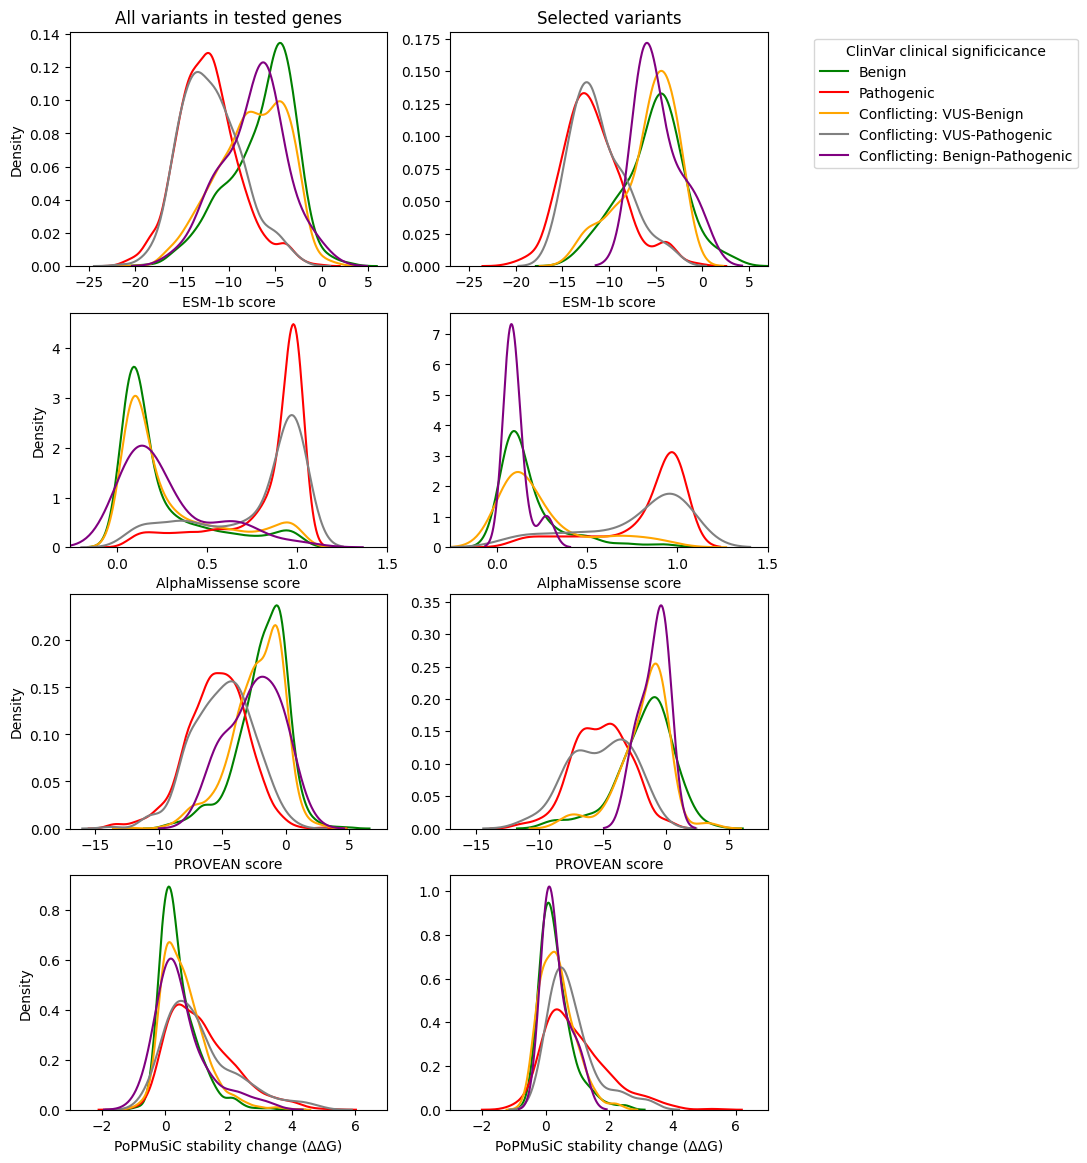

In [ ]:
range_d = {'esm1b':(-27,7),
           'alpha_missense':(-.26,1.5),
           'provean':(-17,8),
           'pop_music':(-3,7),
           'solvant_acc':(0,100),
           'af_plddt':(0,100),
           }

fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(9,14))

for row, assay in zip(axs, ['esm1b','alpha_missense','provean','pop_music']):

    for cs,color in zip(['Benign','Pathogenic'],['green','red']):
        df = clinvar_onepercent[clinvar_onepercent.clinical_significance_simple == cs]
        dfo = clinvar_onepercent[(clinvar_onepercent.clinical_significance_simple == cs)&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=cs)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=cs)
    
    for conflicting_class,color in zip(['Conflicting: Benign-VUS','Conflicting: Pathogenic-VUS','Conflicting: Benign-Pathogenic'],['orange','gray','purple']):
        df = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')]
        dfo = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=conflicting_class)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=conflicting_class)
    
    
    row[0].set_xlim(range_d[assay])
    row[1].set_xlim(range_d[assay])

    if assay == 'esm1b':
        row[1].legend(loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')
        row[0].set_title('All variants in tested genes')
        row[1].set_title('Selected variants')

    axs[0][1].set_ylabel('')
    axs[1][1].set_ylabel('')
    axs[2][1].set_ylabel('')
    axs[3][1].set_ylabel('')

    axs[0][0].set_xlabel('ESM-1b score')
    axs[0][1].set_xlabel('ESM-1b score')
    axs[1][0].set_xlabel('AlphaMissense score')
    axs[1][1].set_xlabel('AlphaMissense score')
    axs[2][0].set_xlabel('PROVEAN score')
    axs[2][1].set_xlabel('PROVEAN score')
    axs[3][0].set_xlabel('PoPMuSiC stability change (ΔΔG)')
    axs[3][1].set_xlabel('PoPMuSiC stability change (ΔΔG)')

# Edit legend labels using dictionary
legend_label_dict = {
    'Conflicting: Benign-VUS':'Conflicting: VUS-Benign',
    'Conflicting: Pathogenic-VUS':'Conflicting: VUS-Pathogenic',
}
handles, labels = row[1].get_legend_handles_labels()
new_labels = [legend_label_dict.get(label, label) for label in labels]
axs[0][1].legend(handles, new_labels, loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')

plt.show()

In [31]:
with open(f'../1_inputs/data/all_clinvar_annotated_AM_pop_plddt_acc.pkl', 'rb') as f:
    clinvar_annotated_AM = pickle.load(f)

with open(f'../1_inputs/data/all_clinvar_provean_d.pkl', 'rb') as f:
    provean_d = pickle.load(f)

In [32]:
clinvar_annotated_AM

,Name,GeneSymbol,ClinicalSignificance,LastEvaluated,PhenotypeIDS,PhenotypeList,OriginSimple,Assembly,ReviewStatus,NumberSubmitters,...,essentiality,submissions,submissions_unique_tuple,uniprot_id,am_class,am_pathogenicity,aa_pos,plddt,ddg,acc
0,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),FOXRED1,Pathogenic,"Oct 01, 2010","MONDO:MONDO:0032624,MedGen:C4748791,OMIM:618241","Mitochondrial complex 1 deficiency, nuclear ty...",germline,GRCh38,no assertion criteria provided,1,...,"(50.18372387, -0.036830548, 4.09e-11, 8602.5, ...",[Pathogenic],"(Pathogenic,)",Q96CU9,benign,0.3363,430,97.99,1.27,1.75
1,NM_025152.3(NUBPL):c.166G>A (p.Gly56Arg),NUBPL,Conflicting interpretations of pathogenicity,"Jul 05, 2022","MedGen:C3661900|MeSH:D030342,MedGen:C0950123|M...",not provided|Inborn genetic diseases|Mitochond...,germline,GRCh38,"criteria provided, conflicting interpretations",4,...,"(9.74037708999999, -0.286446161, 0.002009882, ...","[VUS, Pathogenic, VUS, VUS]","(Pathogenic, VUS)",Q8TB37,pathogenic,0.6411,56,62.25,0.11,69.56
2,NM_000410.4(HFE):c.845G>A (p.Cys282Tyr),HFE,Conflicting interpretations of pathogenicity; ...,"Dec 01, 2023","MONDO:MONDO:0021001,MedGen:C3469186,OMIM:23520...",Hemochromatosis type 1|not provided|Hereditary...,germline,GRCh38,"criteria provided, conflicting interpretations",43,...,"(16.40865008, 0.39342573, 8.5e-07, 14434.5, 95...","[Pathogenic, VUS, Pathogenic, Pathogenic, Path...","(Benign, Pathogenic, VUS, not provided, other)",Q30201,pathogenic,0.9585,282,96.41,1.50,0.00
3,NM_000410.4(HFE):c.187C>G (p.His63Asp),HFE,Conflicting interpretations of pathogenicity; ...,"Nov 25, 2023","MONDO:MONDO:0021001,MedGen:C3469186,OMIM:23520...",Hemochromatosis type 1|not provided|Hereditary...,germline,GRCh38,"criteria provided, conflicting interpretations",45,...,"(16.40865008, 0.39342573, 8.5e-07, 14434.5, 95...","[Pathogenic, Pathogenic, Pathogenic, Pathogeni...","(Benign, Pathogenic, VUS, not provided, other)",Q30201,ambiguous,0.4550,63,94.89,1.30,19.45
4,NM_000410.4(HFE):c.193A>T (p.Ser65Cys),HFE,Conflicting interpretations of pathogenicity,"Nov 01, 2023","MONDO:MONDO:0021001,MedGen:C3469186,OMIM:23520...",Hemochromatosis type 1|Hereditary hemochromato...,germline,GRCh38,"criteria provided, conflicting interpretations",13,...,"(16.40865008, 0.39342573, 8.5e-07, 14434.5, 95...","[Benign, not provided, Pathogenic, VUS, Pathog...","(Benign, Pathogenic, VUS, not provided)",Q30201,benign,0.2754,65,93.62,0.65,37.79
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
617135,NM_052845.4(MMAB):c.571C>G (p.Arg191Gly),MMAB,Likely pathogenic,-,"MONDO:MONDO:0009614,MedGen:C1855102,OMIM:25111...","Methylmalonic aciduria, cblB type",germline,GRCh38,"criteria provided, single submitter",1,...,"(27.99831335, 0.326476014, 0.00387716, 12432.0...",[Pathogenic],"(Pathogenic,)",Q96EY8,pathogenic,0.7819,191,98.89,2.31,29.63
617136,NM_006086.4(TUBB3):c.344C>T (p.Ser115Leu),TUBB3,Uncertain significance,"Jun 04, 2021","MONDO:MONDO:0013541,MedGen:C3808397,OMIM:61403...",Complex cortical dysplasia with other brain ma...,germline,GRCh38,no assertion criteria provided,1,...,"(86.21769773, 6.121141833, 0.960789307, 2380.5...",[VUS],"(VUS,)",Q13509,benign,0.1602,115,97.26,0.35,47.98
617137,NM_021005.4(NR2F2):c.737G>A (p.Arg246His),NR2F2,Likely pathogenic,-,"MONDO:MONDO:0020040,MedGen:C2751824,Orphanet:9...","46,XY disorder of sex development",germline,GRCh38,no assertion criteria provided,1,...,NaN,[Pathogenic],"(Pathogenic,)",P24468,pathogenic,0.8471,246,95.38,0.46,37.48
617138,NM_001918.5(DBT):c.250T>C (p.Trp84Arg),DBT,Likely pathogenic,"Jan 02, 2024","MONDO:MONDO:0009563,MeSH:D008375,MedGen:C00247...",Maple syrup urine disease,unknown,GRCh38,"criteria provided, single submitter",1,...,"(27.3055839999999, 0.930715459, 0.000147622, 1...",[Pathogenic],"(Pathogenic,)",P11182,pathogenic,0.9995,84,94.09,2.24,16.44


In [34]:
provean_d["ENSP00000001146"]

{'Met1Val': -0.93,
 'Met1Ile': -0.86,
 'Met1Leu': -0.61,
 'Met1Glu': -0.8,
 'Met1Gln': -0.46,
 'Met1Asp': -1.24,
 'Met1Asn': -1.1,
 'Met1His': -1.31,
 'Met1Trp': -0.82,
 'Met1Phe': -0.91,
 'Met1Tyr': -0.91,
 'Met1Arg': -1.0,
 'Met1Lys': -0.97,
 'Met1Ser': -0.6,
 'Met1Thr': -0.98,
 'Met1Met': 0.0,
 'Met1Ala': -0.93,
 'Met1Gly': -1.15,
 'Met1Pro': -0.75,
 'Met1Cys': -1.39,
 'Leu2Val': -0.23,
 'Leu2Ile': -0.16,
 'Leu2Leu': 0.0,
 'Leu2Glu': -0.85,
 'Leu2Gln': -0.81,
 'Leu2Asp': -1.05,
 'Leu2Asn': -1.02,
 'Leu2His': -1.05,
 'Leu2Trp': -0.56,
 'Leu2Phe': 0.24,
 'Leu2Tyr': -0.24,
 'Leu2Arg': -1.13,
 'Leu2Lys': -0.98,
 'Leu2Ser': -0.51,
 'Leu2Thr': -0.67,
 'Leu2Met': -0.01,
 'Leu2Ala': -0.38,
 'Leu2Gly': -0.46,
 'Leu2Pro': -0.3,
 'Leu2Cys': -0.85,
 'Phe3Val': -0.23,
 'Phe3Ile': -0.25,
 'Phe3Leu': -0.08,
 'Phe3Glu': -0.47,
 'Phe3Gln': -0.45,
 'Phe3Asp': -0.64,
 'Phe3Asn': -0.77,
 'Phe3His': -0.86,
 'Phe3Trp': -0.77,
 'Phe3Phe': 0.0,
 'Phe3Tyr': -0.36,
 'Phe3Arg': -0.79,
 'Phe3Lys': -0.54,
 'Phe

In [35]:
import gzip

pdb_file = "../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz"
uniprot_id = "Q9BQG0"

pdb_lines = []
with gzip.open(pdb_file, 'rt') as f:
    for i, line in enumerate(f):
        line = line[:-1].split()
        if line[0] == 'ATOM':
            if len(line) == 12: #solve issue for lines with merged columns
                pos = int(line[5])
                res = line[3]
                plddt = line[-2]
                row = [uniprot_id, pdb_file, pos, res, float(plddt)]
                pdb_lines.append(row)

# with open (pdb_file) as f:
#     for i, line in enumerate(f):
#         line = line[:-1].split()
#         if line[0] == 'ATOM':
#             if len(line) == 12: #solve issue for lines with merged columns
#                 pos = int(line[5])
#                 res = line[3]
#                 plddt = line[-2]
#                 row = [uniprot_id,file,pos,res,float(plddt)]
#                 pdb_lines.append(row)

In [ ]:
# pdb_lines

[['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  1,
  'MET',
  39.34],
 ['Q9BQG0',
  '../1_inputs/data/UP000005640_9606_HUMAN_v2/AF-Q9BQG0-F1-model_v2.pdb.gz',
  2,
  